In [1]:
%matplotlib inline
from matplotlib import pyplot as plt
import nest
import numpy as np
import itertools
import pickle
from time import time
from random import shuffle
from pynestml.frontend.pynestml_frontend import generate_nest_target
from msn import MSN
from experiment import ExperimentDAHD, ExperimentSSTS

NEST_SIMULATOR_INSTALL_LOCATION = nest.ll_api.sli_func("statusdict/prefix ::")

new_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.3
 Built: Apr  5 2022 17:48:08

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.



In [2]:
generate_nest_target(input_path="nest_module/msn.nestml",
                target_path="nest_module/nestml_target")



-- The CXX compiler identification is AppleClang 13.0.0.13000029
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/clang++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done

-------------------------------------------------------
nestmlmodule Configuration Summary
-------------------------------------------------------

C++ compiler         : /usr/bin/clang++
Build static libs    : OFF
C++ compiler flags   : 
NEST compiler flags  :  -O2 -std=c++11 -Wall -Xclang -fopenmp  -O3 -DNDEBUG
NEST include dirs    :  -I/opt/homebrew/Cellar/nest/3.3_1/include/nest -I/opt/homebrew/include -I/opt/homebrew/opt/readline/include -I/opt/homebrew/include
NEST libraries flags : -L/opt/homebrew/Cellar/nest/3.3_1/lib/nest -lnestutil -lnest -lsli -lnestkernel -Xclang -fopenmp /opt/homebrew/lib/libltdl.dylib /opt/homebrew/opt/readline/lib/libreadline.dylib /Library/Developer/CommandLineTools/SDKs/MacOS

In [3]:
nest.Install("nestmlmodule")


May 15 11:39:31 Install [Info]: 
    loaded module nestmlmodule


In [4]:
# t = int(time())
# restart_kernel(t, t+1)

msn = MSN(curr=0)
    
# Running example

e_normal = ExperimentDAHD(dopamine_level=0.3, msn=msn)
e_normal.run()


May 15 11:39:36 NodeManager::prepare_nodes [Info]: 
    Preparing 4599 nodes for simulation.

May 15 11:39:36 SimulationManager::start_updating_ [Info]: 
    Number of local nodes: 4599
    Simulation time (ms): 1500
    Number of OpenMP threads: 1
    Not using MPI

May 15 11:39:52 SimulationManager::run [Info]: 
    Simulation finished.

May 15 11:39:52 NodeManager::prepare_nodes [Info]: 
    Preparing 4599 nodes for simulation.

May 15 11:39:52 SimulationManager::start_updating_ [Info]: 
    Number of local nodes: 4599
    Simulation time (ms): 1
    Number of OpenMP threads: 1
    Not using MPI

May 15 11:39:52 SimulationManager::run [Info]: 
    Simulation finished.

May 15 11:39:52 NodeManager::prepare_nodes [Info]: 
    Preparing 4599 nodes for simulation.

May 15 11:39:52 SimulationManager::start_updating_ [Info]: 
    Number of local nodes: 4599
    Simulation time (ms): 1
    Number of OpenMP threads: 1
    Not using MPI

May 15 11:39:52 SimulationManager::run [Info]: 
    S

Text(0.5, 1.0, 'MSN')

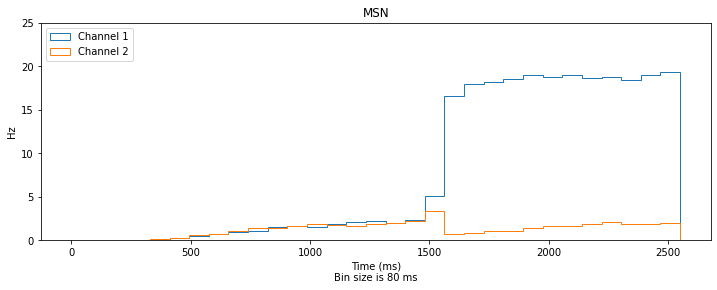

In [4]:
# Plotting results

e = e_normal
plt.rcParams['figure.figsize'] = [12.0, 4.0]
channels = [0,1]
plt.rcParams['font.size'] = 15
e.msn.plot_activity('msn', channels=channels, time_bin=80, y_range=(0,25)); plt.title('MSN')

In [5]:
def rasterplot(
    ax, nucleus_name='msn', channels=0, n_neurons=40, time_bin=50.0, time_axis=True, 
    alpha_spike=0.2, alpha_background=0.125
):
    ax1 = ax
#     ax1.set_title(nucleus_name)
    ax1.set_ylabel(nucleus_name)
    nucleus_name = nucleus_name.lower()

    if type(channels) is not list:
        channels = [channels]
    
    spikes = []
    for i, channel in enumerate(channels):
        # Set background
        ax1.axhspan(i*n_neurons, (i+1)*n_neurons, facecolor=new_colors[i], alpha=alpha_background)
        
        # Plot events        
        detector = msn.__getattribute__('spikedetector_' + nucleus_name + '_channels')[channel]
        senders = nest.GetStatus(detector)[0]['events']['senders']
        times = nest.GetStatus(detector)[0]['events']['times']

        spikes_dict = {sender: [] for sender in senders}
        for sender,time in zip(senders,times):
            spikes_dict[sender].append(time)
        spikes_list = list(spikes_dict.values())
        shuffle(spikes_list)
        spikes += spikes_list[:n_neurons]
    ax1.set_yticks([])
#     ax1.eventplot(spikes, colors='black', alpha=0.4)
    for i, t in enumerate(spikes):
        ax1.plot(t, [i]*len(t), 'o', markersize=1, color='black', alpha=alpha_spike)
    ax1.set_xlim(0,2550)
    ax1.tick_params(labelsize=plt.rcParams['font.size']*0.75)
    if not time_axis: ax1.set_xticks([])
    
    
    ax2 = ax1.twinx()
    for i, channel in enumerate(channels):
        detector = msn.__getattribute__('spikedetector_' + nucleus_name + '_channels')[channel]
        senders = nest.GetStatus(detector)[0]['events']['senders']
        times = nest.GetStatus(detector)[0]['events']['times']

        n_senders = len(set(senders))
        n_bins = int( (max(times)-min(times)) / time_bin)
        
        ax2.hist(
            times,
            bins = n_bins, 
            histtype = 'step', 
            weights = np.ones_like(times) / (n_senders * (time_bin / 1000.0)),
            label = 'ch{}'.format(i),
            linewidth = 2.0,
        )
        ax2.tick_params(labelsize=plt.rcParams['font.size']*0.75)
    
    ax2.axvline(x=1500, linestyle='--', color=new_colors[2])

    
def plot_input_from_cortex(ax):
    time_values = np.linspace(0,2550,num=2550)
    y1 = np.ones_like(time_values)
    y2 = np.ones_like(time_values)
    y1 *= 5
    y2 *= 5
    for i in range(25):
        y1[1500+i] += (i)*2e-2
        y1[1525+i] += (25+i)*2e-2
        y2[1500+i] += (i)*2e-2
        y2[1525+i] += (25-i)*2e-2
    y1[1550:] = 6.0

    ax.plot(time_values, y1)
    ax.plot(time_values, y2)
    ax.set_xlim(0,2550)
    ax.set_ylabel('Ctx')
    ax.yaxis.set_ticks([5, 6])
    ax.yaxis.set_ticks_position('right')
    ax.xaxis.set_ticks([])
    ax.tick_params(labelsize=plt.rcParams['font.size']*0.75)
    ax.axvline(x=1500, linestyle='--', color=new_colors[2])

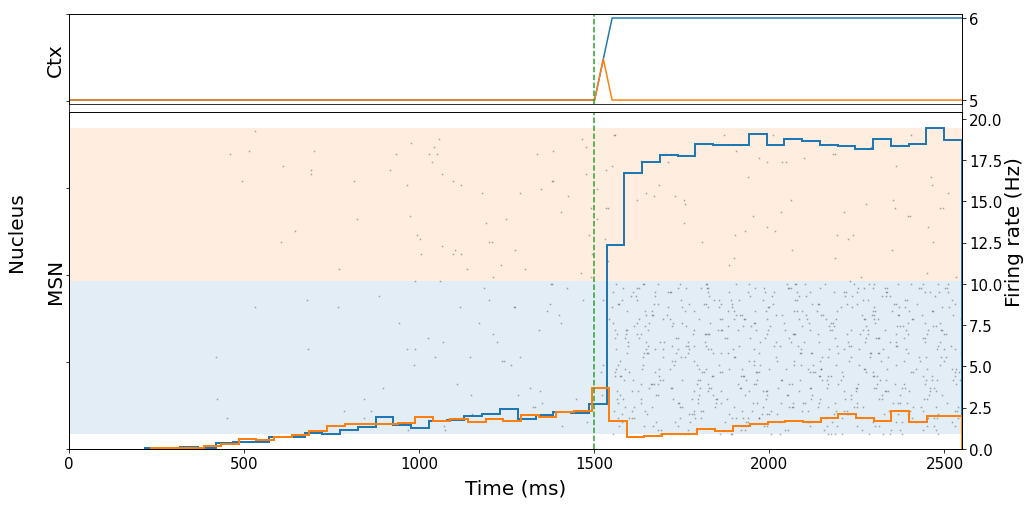

In [6]:
plt.rcParams['figure.figsize'] = [16.0, 8.0]#[6.0, 8.0]
plt.rcParams['font.size'] = 20

fig = plt.figure()
ax_ctx = plt.subplot2grid((9,1), (0,0), rowspan=2)
ax_msn = plt.subplot2grid((9,1), (2,0), rowspan=7)


plot_input_from_cortex(ax_ctx)

rasterplot(ax_msn, 'MSN', channels=[0,1])

ax1 = fig.add_subplot(111, frameon=False)
ax1.tick_params(labelcolor='none', top=False, bottom=False, left=False, right=False)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Nucleus')

ax2 = ax1.twinx()
ax2.tick_params(labelcolor='none', top=False, bottom=False, left=False, right=False)
ax2.set_ylabel('Firing rate (Hz)')
ax2.yaxis.set_label_position('right')

# plt.tight_layout()
plt.legend(loc='upper left')

plt.savefig("general_behaviour.svg")
plt.savefig("general_behaviour.png", dpi=300, transparent=True)

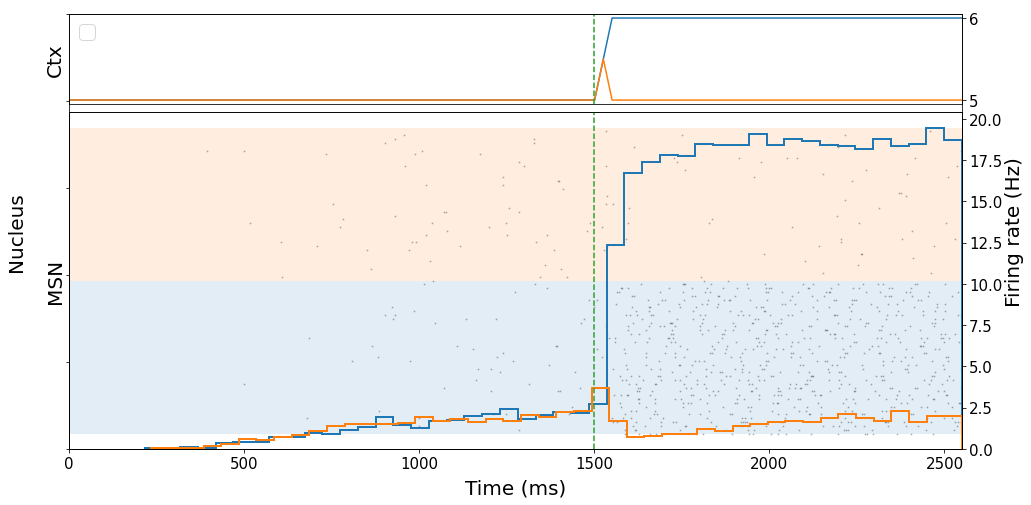

In [6]:
plt.rcParams['figure.figsize'] = [16.0, 8.0]#[6.0, 8.0]
plt.rcParams['font.size'] = 20

fig = plt.figure()
ax_ctx = plt.subplot2grid((9,1), (0,0), rowspan=2)
ax_msn = plt.subplot2grid((9,1), (2,0), rowspan=7)


plot_input_from_cortex(ax_ctx)

rasterplot(ax_msn, 'MSN', channels=[0,1])

ax1 = fig.add_subplot(111, frameon=False)
ax1.tick_params(labelcolor='none', top=False, bottom=False, left=False, right=False)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Nucleus')

ax2 = ax1.twinx()
ax2.tick_params(labelcolor='none', top=False, bottom=False, left=False, right=False)
ax2.set_ylabel('Firing rate (Hz)')
ax2.yaxis.set_label_position('right')

# plt.tight_layout()
plt.legend(loc='upper left')

plt.savefig("general_behaviour.svg")
plt.savefig("general_behaviour.png", dpi=300, transparent=True)

Text(0.5, 1.0, 'MSN')

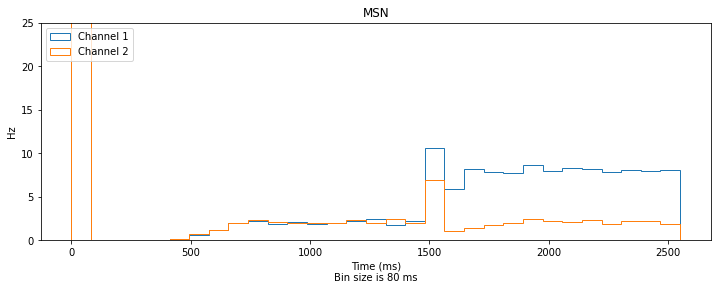

In [4]:
# 260 pA
e2 = e_normal2
plt.rcParams['figure.figsize'] = [12.0, 4.0]
channels = [0,1]
plt.rcParams['font.size'] = 15
e2.msn.plot_activity('msn', channels=channels, time_bin=80, y_range=(0,25)); plt.title('MSN')

Text(0.5, 1.0, 'MSN')

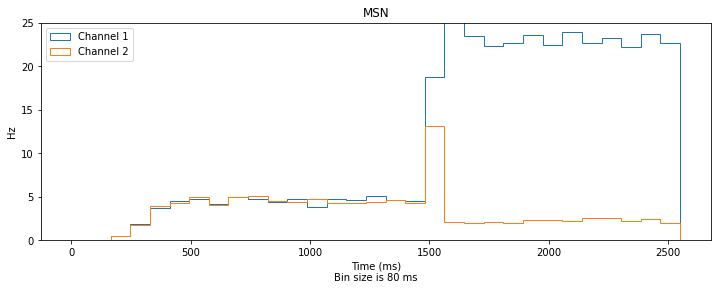

In [5]:
#280pA
e2 = e_normal2
plt.rcParams['figure.figsize'] = [12.0, 4.0]
channels = [0,1]
plt.rcParams['font.size'] = 15
e2.msn.plot_activity('msn', channels=channels, time_bin=80, y_range=(0,25)); plt.title('MSN')

In [3]:
from msn_params import params

def compute_transfer(i_mean=(200.0, 300.0, 10.0)):
        #######################################################################
        # We loop through all possible combinations of `(I_mean, I_sigma)`
        # and measure the output rate of the neuron.

        i_range = np.arange(*i_mean)
        rate = np.zeros((i_range.size))
        nest.set_verbosity('M_WARNING')
        for n, i in enumerate(i_range):
            print('I  =  {0}'.format(i))
            rate[n] = output_rate(i)
        return rate

def output_rate(mean):
        msn = MSN(curr=mean)
        # para = params.copy()

        # msn_d1 = nest.Create('msn', para.net.msn.d1_n)
        # nest.SetStatus(msn_d1, para.neuron.msn_d1)
        # nest.SetStatus(msn_d1, {'I_e': mean})
        # spikedetector_msn_d1 = nest.Create('spike_recorder')
        # nest.Connect(msn_d1, spikedetector_msn_d1)

        # Running example
        nest.ResetKernel()
        e_normal = ExperimentDAHD(dopamine_level=0.3, msn=msn)
        e_normal.run()
        detector = msn.__getattribute__('spikedetector_msn_d1')
        # senders = nest.GetStatus(detector)[0]['events']['senders']
        # times = nest.GetStatus(detector)[0]['events']['times']

        rate = detector.n_events * 1000. / (1. * len(msn.msn_d1) * 2550)
        print(rate)
        return rate

In [6]:
compute_transfer()

I  =  200.0
msn length: 1146
I  =  210.0
msn length: 1146
I  =  220.0
msn length: 1146
I  =  230.0
msn length: 1146
I  =  240.0
msn length: 1146
I  =  250.0
msn length: 1146
I  =  260.0
msn length: 1146
I  =  270.0
msn length: 1146
I  =  280.0
msn length: 1146
I  =  290.0
msn length: 1146


array([30.52150703, 31.79413476, 33.01680183, 34.20661807, 35.36632105,
       36.48735585, 37.69325531, 38.85398487, 40.02087397, 41.16107176])

In [10]:
nucleus_spike_times = [d[0]['times'] for d in [nest.GetStatus(d1_det[i], 'events') for i, d in enumerate(d1_det)]]
n_senders_channel = [len(nest.GetConnections(target=d1_det[i])) for i,d in enumerate(d1_det)]

In [12]:
[nest.GetStatus(d1_det[i], 'events') for i, d in enumerate(d1_det)]

[({'senders': array([190, 336, 248, ..., 459, 460, 461]),
   'times': array([23.6, 23.1, 24.7, ..., 48.3, 48.2, 48.2])},),
 ({'senders': array([508, 889, 659, ..., 592, 592, 592]),
   'times': array([  21.5,   22. ,   23. , ..., 2436.9, 2439.7, 2442.3])},),
 ({'senders': array([ 942, 1099, 1139, ..., 1122, 1122, 1020]),
   'times': array([  24. ,   27.5,   29.2, ..., 2539.5, 2546.8, 2547.4])},)]

In [ ]:
np.ones_like(ch) / (n_senders * (time_bin / 1000.0)